# IMPORTS

In [13]:
pip install -U scikit-image

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [12]:
pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/38.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/38.6 MB 435.7 kB/s eta 0:01:29
   ---------------------------------------- 0.1/38.6 MB 491.5 kB/s eta 0:01:19
   ---------------------------------------- 0.1/38.6 MB 774.0 kB/s eta 0:00:50
   ---------------------------------------- 0.2/38.6 MB 958.4 kB/s eta 0:00:41
   ---------------------------------------- 0.3/38.6 MB 1.1 MB/s eta 0:00:37
   ---------------------------------------- 0.4/38.6 MB 1.2 MB/s eta 0:00:33
   ---------------------------------------- 0.4/38.6 MB 1.2 MB/s eta 0:00:33
    --------------------------------------- 0.7/38.6 MB 1.6 MB/s eta 0:00:24
    --------------------------------------- 0.9/38.6 MB 2.0 MB/s eta 0:00:20
   - -------------------------------------- 1.4/38.6 MB 2.8 MB/s eta 0:00:14
   -

In [11]:
!pip install cv2

Defaulting to user installation because normal site-packages is not writeable


ERROR: Could not find a version that satisfies the requirement cv2 (from versions: none)
ERROR: No matching distribution found for cv2


In [5]:
!pip install statsmodels

   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.0 MB ? eta -:--:--
   ---------- ----------------------------- 2.6/10.0 MB 8.4 MB/s eta 0:00:01
   ------------------- -------------------- 5.0/10.0 MB 9.7 MB/s eta 0:00:01
   ------------------------------ --------- 7.6/10.0 MB 10.2 MB/s eta 0:00:01
   ------------------------------------- -- 9.4/10.0 MB 10.0 MB/s eta 0:00:01
   ---------------------------------------- 10.0/10.0 MB 9.3 MB/s eta 0:00:00


In [2]:
from platform import python_version
print(python_version())

3.8.20


In [3]:
import statsmodels.api as sm

In [4]:
import numpy as np
import nibabel as nib
import nibabel.streamlines as nibs
import os
import tensorflow as tf
from PIL import Image
import PIL
import skimage.transform as skTrans
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (BatchNormalization, SeparableConv2D, Conv2D, MaxPooling2D, Activation, Flatten, Dropout, Dense)
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.models import load_model


import matplotlib.pyplot as plt
import os
import cv2

from timeit import default_timer as timer

#from tensorflow.keras.layers import Dense, Activation, Dropout, Flatten, Conv2D, MaxPooling2D
#from tensorflow.keras.layers.normalization import BatchNormalization

np.random.seed(1000)

In [5]:
#Female Datasets
            
aut_path = "D:/ABIDE-Dataset/04 Datasets for Pappers/Paper_03 Labeled Data - Gender-specific Autism/ABIDE_I/F-autism/"
cnt_path = "D:/ABIDE-Dataset/04 Datasets for Pappers/Paper_03 Labeled Data - Gender-specific Autism/ABIDE_I/F-control/"

In [6]:
#test_aut_path = "AUTISTIC_VAL//"
#test_cnt_path = "CONTROL_VAL//"
#test_aut_path = "C:/Users/ZhaoBIT-GPU/Python-Projects/ASD-R2/ABIDE-Dataset//DATASET-1/AUTISTIC_VAL/"
#test_cnt_path = "C:/Users/ZhaoBIT-GPU/Python-Projects/ASD-R2/ABIDE-Dataset//DATASET-1/CONTROL_VAL/"

#Male Datasets
#test_aut_path = "C:/Users/ZhaoBIT-GPU/Python-Projects/ASD-R2/ABIDE-Dataset//DATASET-Gender/AUT_M_VAL/"
#test_cnt_path = "C:/Users/ZhaoBIT-GPU/Python-Projects/ASD-R2/ABIDE-Dataset//DATASET-Gender/CON_M-VAL/"

#Female Datasets
test_aut_path = "D:/ABIDE-Dataset/04 Datasets for Pappers/Paper_03 Labeled Data - Gender-specific Autism/ABIDE_I/AUT_F_VAL/"
test_cnt_path = "D:/ABIDE-Dataset/04 Datasets for Pappers/Paper_03 Labeled Data - Gender-specific Autism/ABIDE_I/CON_F_VAL/"

In [7]:
def to_arr(path):
    return np.array(nib.load(path).dataobj)

In [8]:
len(os.listdir(aut_path))

143

In [9]:
len(os.listdir(cnt_path))

136

In [10]:
len(os.listdir(test_aut_path))

36

In [11]:
len(os.listdir(test_cnt_path))

34

# CREATING LABELS

In [12]:
'''
labels = []
for i in range(len(os.listdir(aut_path))):
    im = nib.load(aut_path+i)
    if im.ndim == 3:
        labels.append([1,0])
for i in range(len(os.listdir(cnt_path))):
    im = nib.load(cnt_path+i)
    if im.ndim == 3:
        labels.append([0,1])
labels = np.array(labels)
'''
print("Labels has been added to the Array Conversion Code Block")

Labels has been added to the Array Conversion Code Block


# READING INPUT NIFTI FILES AND CONVERTING IT INTO ARRAYS

In [13]:
# NON-Optimized way of converting NIFTI Image files to Arrays
'''
start = timer()
auts = []
cnts = []

for i in os.listdir(aut_path):
    im = nib.load(aut_path+i).get_fdata()
    im = im[:,:, :1]
    r = tf.image.resize(im, [224,224])
    #print(i)
    auts.append(r)
for i in os.listdir(cnt_path): 
    im = nib.load(cnt_path+i).get_fdata()
    im = im[:,:, :1]
    r = tf.image.resize(im, [224,224])
    #print(i)
    cnts.append(r)
    
print('done')
print("Without GPU:", timer()-start)
'''
print("UN_OPTIMIZED CODE")

UN_OPTIMIZED CODE


In [14]:
# Testing Nifty Images to 3 or 4 Dimensions
im = nib.load(aut_path+"4anat.nii.gz")

'''
# Code snipt for displaying Image variants  No.of Images X Times Stamps of Images
for i in range(41):
    for j in range(432):
        test = im.dataobj[:, :,i,j]
        print(test.shape)
        plt.imshow(test)
        plt.show()
'''
       
#print(im)
print(im.shape)
#print(im.ndim)       Image shape dimessions display

(256, 224, 192)


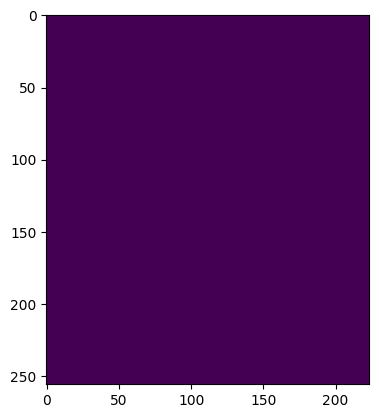

In [15]:
mri_img = im.dataobj[:, :,190]
plt.imshow(mri_img)
plt.show()

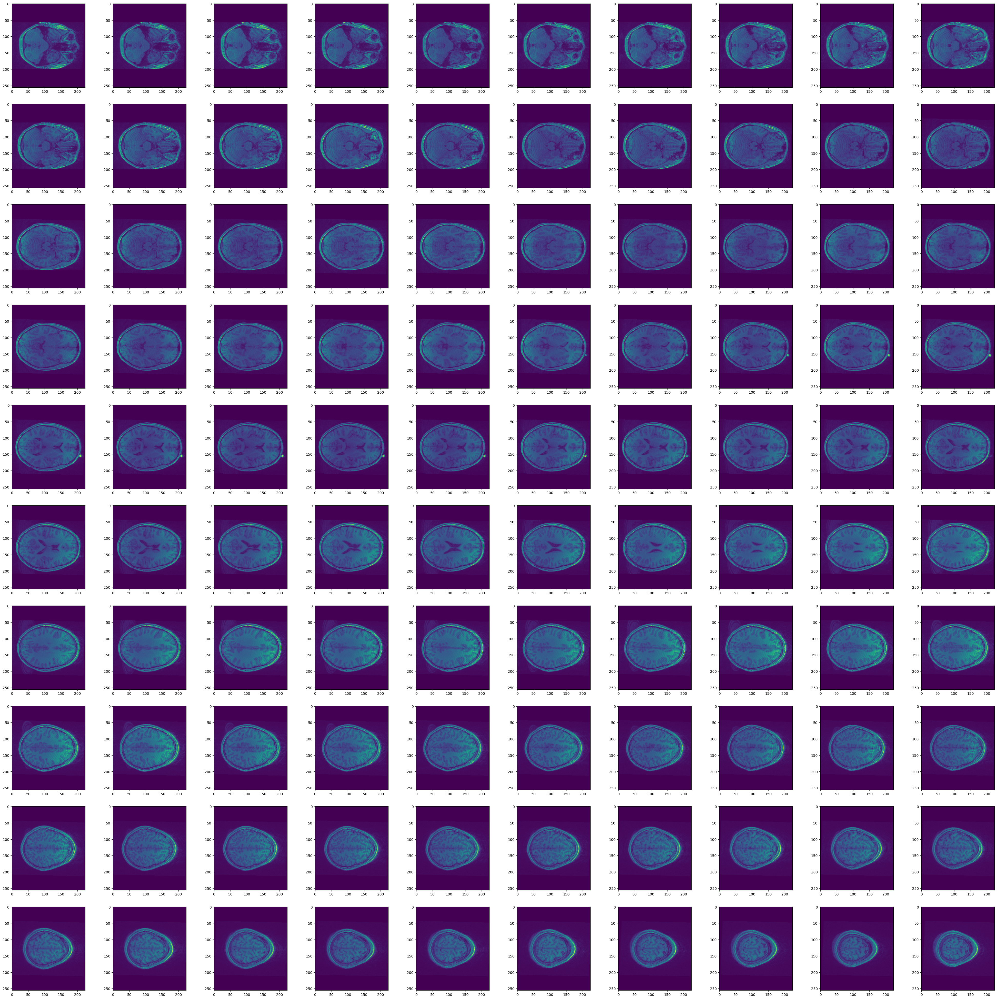

In [16]:
for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.imshow(im.dataobj[:,:,50+i])
    plt.gcf().set_size_inches(50, 50)
        #test = im.dataobj[:, :,i,j]
        #print(test.shape)
        #plt.imshow(test)
plt.show()

In [17]:
start = timer()
auts = []
cnts = []
labels = []

for i in os.listdir(aut_path):
    im = nib.load(aut_path+i)
    if im.ndim == 3:
        im = im.dataobj[:,:, :3]
        r = cv2.resize(im, [224,224])
        labels.append([1,0])
        auts.append(r)
    #print(i)
    #auts.append(r)
    
for i in os.listdir(cnt_path):                # Fetching the Directory Path
    im = nib.load(cnt_path+i)                 # Concatinating the Nii image name to the Directory Path
    if im.ndim == 3:                          # Shape Parameters check, Either (row, col, chanel, Time_series)
        im = im.dataobj[:,:, :3]              # Resizing the Image to (224,224, 1) shape
        r = cv2.resize(im, [224,224])
        labels.append([0,1] )
        cnts.append(r)
    #print(i)
    #cnts.append(r)
labels = np.array(labels)
print('done')
print("Execution Time:", timer()-start)

done
Execution Time: 1.2055057000000033


In [18]:
print(len(auts))

84


In [19]:
print(len(cnts))

130


In [20]:
labels

array([[1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1,

In [21]:
#np.warnings.filterwarnings('ignore', category=np.VisibleDeprecationWarning)    
auts = np.array(auts)
cnts = np.array(cnts)

# auts = tf.convert_to_tensor(auts)
# cnts = tf.convert_to_tensor(cnts)

In [22]:
type(auts)

numpy.ndarray

In [23]:
auts.shape

(84, 224, 224, 3)

In [24]:
cnts.shape

(130, 224, 224, 3)

# Training Samples Concatination

In [25]:
images = np.concatenate([auts, cnts])

In [26]:
images.shape, labels.shape

((214, 224, 224, 3), (214, 2))

In [27]:
images, labels = np.array(images), np.array(labels)

In [28]:
images.shape, labels.shape

((214, 224, 224, 3), (214, 2))

# CREATING THE 4 MODELS NAMELY (RESNET, VGGNET, ALEXNET AND CNN)

In [29]:
def get_resnet_model():
    res_model = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=None,
        input_shape=(224,224,3),
        pooling=None,
        classes=2
    )
    for layer in res_model.layers[:143]:
        layer.trainable = False
        
    model = tf.keras.models.Sequential()
    model.add(res_model)
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(2, activation='softmax'))
    return model

def get_impv_resnet_model():
    res_model = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        #input_tensor=2,
        input_shape=(224,224,3),
        pooling=None,
        classes=2
    )
    for layer in res_model.layers[:143]:
        layer.trainable = False
        
    # Creating new model
    model = tf.keras.models.Sequential()
    model.add(res_model)
    
    # Additional layers for improved performance
    model.add(tf.keras.layers.GlobalAveragePooling2D())
    model.add(tf.keras.layers.Dense(256, activation='relu'))
    model.add(tf.keras.layers.Dropout(0.5))
    model.add(tf.keras.layers.Dense(128, activation='relu'))
    model.add(tf.keras.layers.Dropout(0.3))

    # Output layer with softmax activation
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(2, activation='softmax'))

    #optimized learning rate and decay
    #optimizer = tf.keras.optimizers.Adam(learning_rater=0.0001, decay=1e-6)
    return model


def get_vgg_model():
    vgg_model = tf.keras.applications.VGG16(
        include_top=False,
        weights="imagenet",
        input_tensor=None,
        input_shape=(224,224,3),
        pooling=None,
        classes=2
    )
    for layer in vgg_model.layers[:143]:
        layer.trainable = False
    model = tf.keras.models.Sequential()
    model.add(vgg_model)
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(2, activation='softmax'))
    return model

def get_cnn_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(32, (3,3), padding='same', activation=tf.nn.relu, kernel_regularizer = tf.keras.regularizers.l1( l=0.02),
                               input_shape=(224, 224, 3)),
        tf.keras.layers.MaxPooling2D((2, 2), strides=2),
        #tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Conv2D(64, (2,2), padding='same', activation=tf.nn.relu, kernel_regularizer = tf.keras.regularizers.l1( l=0.02)),
        tf.keras.layers.MaxPooling2D((2, 2), strides=2),
        #tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Conv2D(64, (2,2), padding='same', activation=tf.nn.relu, kernel_regularizer = tf.keras.regularizers.l1( l=0.02)),
        tf.keras.layers.MaxPooling2D((2, 2), strides=1),
        #tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation=tf.nn.relu, kernel_regularizer =tf.keras.regularizers.l1( l=0.01)),
        tf.keras.layers.Dense(16, activation=tf.nn.relu),
        tf.keras.layers.Dense(2, activation=tf.nn.softmax)
    ])
    return model

In [30]:
def eCNNNet():
    model = Sequential()

    # Layer 1: Convolutional Layer
    model.add(tf.keras.layers.Conv2D(32, kernel_size=(3, 3), strides=(1, 1), activation='relu', input_shape=(224, 224, 3), padding="same"))
    model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    # Layer 2: Convolutional Layer
    model.add(tf.keras.layers.Conv2D(64, kernel_size=(3, 3), strides=(1, 1), activation='relu', padding="same"))
    model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    # Layer 3: Convolutional Layer
    model.add(tf.keras.layers.Conv2D(128, kernel_size=(3, 3), strides=(1, 1), activation='relu', padding="same"))
    model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    # Layer 4: Convolutional Layer
    model.add(tf.keras.layers.Conv2D(256, kernel_size=(3, 3), strides=(1, 1), activation='relu', padding="same"))
    model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))

    # Flatten
    model.add(tf.keras.layers.Flatten())

    # Fully Connected Layer 1
    model.add(tf.keras.layers.Dense(512, activation='relu'))

    # Fully Connected Layer 2
    model.add(tf.keras.layers.Dense(256, activation='relu'))

    # Output Layer
    model.add(tf.keras.layers.Dense(2, activation='softmax'))

    return model

In [31]:
#!pip install ktrain

In [32]:
def get_alexnet_model():
    #Instantiation
    AlexNet = Sequential()

    #1st Convolutional Layer
    AlexNet.add(Conv2D(filters=96, input_shape=(224,224,3), kernel_size=(3,3), strides=(2,2), padding='same'))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))
    AlexNet.add(MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='same'))

    #2nd Convolutional Layer
    AlexNet.add(Conv2D(filters=256, kernel_size=(5, 5), strides=(1,1), padding='same'))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))
    AlexNet.add(MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='same'))

    #3rd Convolutional Layer
    AlexNet.add(Conv2D(filters=384, kernel_size=(3,3), strides=(1,1), padding='same'))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))

    #4th Convolutional Layer
    AlexNet.add(Conv2D(filters=384, kernel_size=(3,3), strides=(1,1), padding='same'))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))

    #5th Convolutional Layer
    AlexNet.add(Conv2D(filters=256, kernel_size=(3,3), strides=(1,1), padding='same'))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))
    AlexNet.add(MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='same'))

    #Passing it to a Fully Connected layer
    AlexNet.add(Flatten())
    # 1st Fully Connected Layer
    AlexNet.add(Dense(4096, input_shape=(32,32,3,)))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))
    # Add Dropout to prevent overfitting
    AlexNet.add(Dropout(0.4))

    #2nd Fully Connected Layer
    AlexNet.add(Dense(4096))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))
    #Add Dropout
    AlexNet.add(Dropout(0.4))

    #3rd Fully Connected Layer
    AlexNet.add(Dense(1000))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('relu'))
    #Add Dropout
    AlexNet.add(Dropout(0.4))

    #Output Layer
    AlexNet.add(Dense(2))
    AlexNet.add(BatchNormalization())
    AlexNet.add(Activation('softmax'))
    
    return AlexNet

In [34]:
model = eCNNNet() # CHANGE THE MODEL HERE (IF YOU WANT TO)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 56, 56, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 56, 56, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 28, 28, 128)      0

In [35]:
from tensorflow.keras.optimizers import SGD
learning_rate = 0.0001
momentum = 0.9  
optimizer = SGD(learning_rate=learning_rate, momentum=momentum)
#optimizer = tf.keras.optimizers.Adam(learning_rate, decay=1e-6)

In [36]:
#loss = 'categorical_crossentropy',
model.compile(optimizer = optimizer,
              loss = 'categorical_crossentropy',      # categorical_crossentropy
              #loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

In [37]:
# model.compile(optimizer = 'adam', loss = 'categorical_crossentropy',
              #loss=tf.keras.losses.SparseCategoricalCrossentropy(),
#              metrics=['accuracy'])

In [38]:
BATCH_SIZE = 16

In [ ]:
Model_fit = model.fit(images, labels, epochs=50, batch_size = BATCH_SIZE)

Epoch 1/50


In [312]:
results = model.evaluate(images, labels, verbose = 0)
results[1]

0.7558139562606812

In [313]:
print(Model_fit.history.keys())

dict_keys(['accuracy', 'loss'])


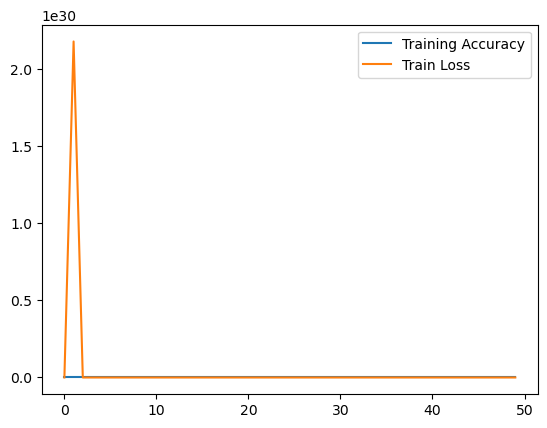

In [314]:

plt.plot(Model_fit.history["accuracy"], label = "Training Accuracy")
plt.plot(Model_fit.history["loss"], label = "Train Loss")
plt.legend(loc="best")
plt.show()

In [296]:
predicted = model.predict(images)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


In [297]:
from sklearn.metrics import confusion_matrix, classification_report

# GENERATING TEST SET AND CHECKING MODEL ACCURACY

In [299]:
def get_test():
    aut_test = []
    cnt_test = []
    test_labels = []
    for i in os.listdir(test_aut_path):
        im = nib.load(test_aut_path+i)
        if im.ndim == 3:
            im = im.dataobj[:,:, :3]
            r = tf.image.resize(im, [224,224])
            test_labels.append([1,0])
            aut_test.append(r)
    for i in os.listdir(test_cnt_path): 
        im = nib.load(test_cnt_path+i)
        if im.ndim == 3:
            im = im.dataobj[:,:, :3]
            r = tf.image.resize(im, [224,224])
            test_labels.append([1,0])
            cnt_test.append(r)
    test_labels = np.array(test_labels)
    aut_test = np.array(aut_test)
    cnt_test = np.array(cnt_test)
    test_images = np.concatenate([aut_test, cnt_test])
    return test_images, test_labels

In [300]:
test_images, test_labels = get_test()

In [301]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(test_images, test_labels)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0446 - loss: 1.4532


In [302]:
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 1.4846587181091309
Test Accuracy: 0.0357142873108387


In [303]:
#pred = model.predict(test_images)
pred = model.predict(test_images, batch_size=8, verbose=0)
pred_lables = tf.argmax(pred, axis=1)
y_test_new = np.argmax(test_labels, axis=1)

In [304]:
y_test_new[1]

0

In [238]:
print(pred)

[[2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [1.0000000e+00 3.0085696e-35]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539045e-01 7.2460955e-01]
 [2.7539

In [239]:
print(y_test_new)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [241]:
from sklearn.metrics import classification_report,confusion_matrix
model.evaluate(test_images, test_labels, verbose = 0)

[1.3657574653625488, 0.01785714365541935]

# RESULTS

### RESNET 48.72%

### VGGNET 54.3%

### ALEXNET 47.49%

### CNN 78.57%